In [1]:
# WEEK 4: EDA AND FEATURE ENGINEERING

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy import stats
from datetime import datetime
import json
import re

sns.set_theme(style="whitegrid")

# Path to the cleaned dataset generated in Week 3
file_path = Path(
    r"C:\Users\ARYAN KATAKDHOND\Downloads\archive\week3_outputs\cleaned_skincare_reviews.csv"
)

if not file_path.exists():
    raise FileNotFoundError(
        f"Cleaned dataset not found: {file_path}\n"
        "Check that your Week 3 output file exists."
    )

df = pd.read_csv(file_path, low_memory=False)
raw_shape = df.shape

# Create a separate copy for Week 4 analysis
eda_df = df.copy(deep=True)

# Create an output folder for charts and reports
output_dir = file_path.parent.parent / "week4_outputs"
output_dir.mkdir(parents=True, exist_ok=True)

print("Dataset loaded successfully!")
print("Rows:", eda_df.shape[0])
print("Columns:", eda_df.shape[1])
print("Output folder:", output_dir)

ModuleNotFoundError: No module named 'scipy'

In [2]:
%pip install scipy

   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.6 MB ? eta -:--:--
    --------------------------------------- 0.5/36.6 MB 1.4 MB/s eta 0:00:26
    --------------------------------------- 0.8/36.6 MB 1.3 MB/s eta 0:00:28
   - -------------------------------------- 1.0/36.6 MB 1.2 MB/s eta 0:00:29
   - -------------------------------------- 1.3/36.6 MB 1.3 MB/s eta 0:00:28
   - -------------------------------------- 1.6/36.6 MB 1.2 MB/s eta 0:00:29
   -- ------------------------------------- 1.8/36.6 MB 1.3 MB/s eta 0:00:28
   -- ------------------------------------- 2.1/36.6 MB 1.3 MB/s eta 0:00:28
   -- ------------------------------------- 2.4/36.6 MB 1.3 MB/s eta 0:00:27
   -- ------------------------------------- 2.6/36.6 MB 1.3 MB/s eta 0:00:27
   --- ------------------------------------ 2.9/36.6 MB 1.3 MB/s eta 0:00:27
   --- ------------------------------------ 3.1/36.6 MB 1.3 MB/s eta 0:00:26
   --- ------

In [1]:
import scipy
from scipy import stats

print("SciPy installed successfully!")
print("SciPy version:", scipy.__version__)
import scipy
from scipy import stats

print("SciPy installed successfully!")
print("SciPy version:", scipy.__version__)

SciPy installed successfully!
SciPy version: 1.18.1
SciPy installed successfully!
SciPy version: 1.18.1


In [2]:
from scipy import stats

In [3]:
# STEP 2: DATA QUALITY PROFILE

print("=" * 50)
print("WEEK 4: INITIAL DATA QUALITY CHECK")
print("=" * 50)

# Dataset dimensions
print("\nDataset shape:", eda_df.shape)

# Check required columns
required_columns = ["rating", "review_text"]

for col in required_columns:
    if col not in eda_df.columns:
        raise ValueError(f"Required column missing: {col}")

print("\nRequired columns are available.")

# Check data types
print("\nColumn data types:")
display(eda_df.dtypes.astype(str).to_frame("Data Type"))

# Check missing values
quality_report = pd.DataFrame({
    "Data Type": eda_df.dtypes.astype(str),
    "Missing Count": eda_df.isna().sum(),
    "Missing Percentage": (
        eda_df.isna().mean() * 100
    ).round(2),
    "Unique Values": eda_df.nunique(dropna=True)
})

quality_report = quality_report.sort_values(
    "Missing Percentage",
    ascending=False
)

display(quality_report)

# Validate ratings
eda_df["rating"] = pd.to_numeric(
    eda_df["rating"],
    errors="coerce"
)

invalid_ratings = (
    ~eda_df["rating"].between(1, 5)
).sum()

# Check blank review text
blank_reviews = (
    eda_df["review_text"].isna()
    | eda_df["review_text"]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
).sum()

print("\nExact duplicate rows:", eda_df.duplicated().sum())
print("Invalid or missing ratings:", int(invalid_ratings))
print("Missing or blank reviews:", int(blank_reviews))

# Save quality report
quality_report.to_csv(
    output_dir / "week4_data_quality_profile.csv"
)

print("\nQuality profile saved successfully!")

WEEK 4: INITIAL DATA QUALITY CHECK


NameError: name 'eda_df' is not defined

In [4]:
# STEP 1: Reload Week 3 cleaned dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from datetime import datetime
import json
import re

from scipy import stats

sns.set_theme(style="whitegrid")

# Path to your Week 3 cleaned dataset
file_path = Path(
    r"C:\Users\ARYAN KATAKDHOND\Downloads\archive\week3_outputs\cleaned_skincare_reviews.csv"
)

if not file_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {file_path}\n"
        "Check that your Week 3 cleaned CSV exists."
    )

# Load data and create the analysis copy
df = pd.read_csv(file_path, low_memory=False)
eda_df = df.copy(deep=True)

# Create the Week 4 output folder
output_dir = file_path.parent.parent / "week4_outputs"
output_dir.mkdir(parents=True, exist_ok=True)

print("Dataset loaded successfully!")
print("Rows:", eda_df.shape[0])
print("Columns:", eda_df.shape[1])
print("SciPy version:", stats.__doc__ is not None)
print("Output folder:", output_dir)

Dataset loaded successfully!
Rows: 116137
Columns: 22
SciPy version: True
Output folder: C:\Users\ARYAN KATAKDHOND\Downloads\archive\week4_outputs


In [5]:
# STEP 2: INITIAL DATA QUALITY CHECK

print("=" * 50)
print("WEEK 4: INITIAL DATA QUALITY CHECK")
print("=" * 50)

# 1. Dataset dimensions
print("\nDataset shape:", eda_df.shape)

# 2. Check required columns
required_columns = ["rating", "review_text"]

for col in required_columns:
    if col not in eda_df.columns:
        raise ValueError(f"Required column missing: {col}")

print("\nRequired columns are available.")

# 3. Column data types
print("\nData types:")
display(eda_df.dtypes.astype(str).to_frame("Data Type"))

# 4. Missing-value summary
quality_report = pd.DataFrame({
    "Data Type": eda_df.dtypes.astype(str),
    "Missing Count": eda_df.isna().sum(),
    "Missing Percentage": (
        eda_df.isna().mean() * 100
    ).round(2),
    "Unique Values": eda_df.nunique(dropna=True)
}).sort_values(
    "Missing Percentage",
    ascending=False
)

print("\nMissing-value report:")
display(quality_report)

# 5. Check duplicates
print(
    "\nExact duplicate rows:",
    eda_df.duplicated().sum()
)

# 6. Check invalid ratings
ratings = pd.to_numeric(
    eda_df["rating"],
    errors="coerce"
)

invalid_ratings = (
    ~ratings.between(1, 5)
).sum()

print("Missing or invalid ratings:", int(invalid_ratings))

# 7. Check blank reviews
blank_reviews = (
    eda_df["review_text"].isna()
    | eda_df["review_text"]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
).sum()

print("Missing or blank reviews:", int(blank_reviews))

# 8. Save quality report
quality_report.to_csv(
    output_dir / "week4_data_quality_profile.csv"
)

print("\nQuality report saved successfully!")

WEEK 4: INITIAL DATA QUALITY CHECK

Dataset shape: (116137, 22)

Required columns are available.

Data types:


,Data Type
unnamed_0,int64
author_id,str
rating,int64
is_recommended,float64
helpfulness,float64
total_feedback_count,int64
total_neg_feedback_count,int64
total_pos_feedback_count,int64
submission_time,str
review_text,str



Missing-value report:


,Data Type,Missing Count,Missing Percentage,Unique Values
helpfulness,float64,56353,48.52,1160
review_title,str,33856,29.15,51872
hair_color,str,19731,16.99,7
eye_color,str,16439,14.15,6
skin_tone,str,15233,13.12,13
is_recommended,float64,11803,10.16,2
skin_type,str,8886,7.65,4
rating,int64,0,0.00,5
unnamed_0,int64,0,0.00,116137
author_id,str,0,0.00,84022



Exact duplicate rows: 0
Missing or invalid ratings: 0
Missing or blank reviews: 0

Quality report saved successfully!


CUSTOMER RATING SUMMARY


,Review Count,Percentage (%)
rating,,
1,6702,5.77
2,5473,4.71
3,8662,7.46
4,21997,18.94
5,73303,63.12


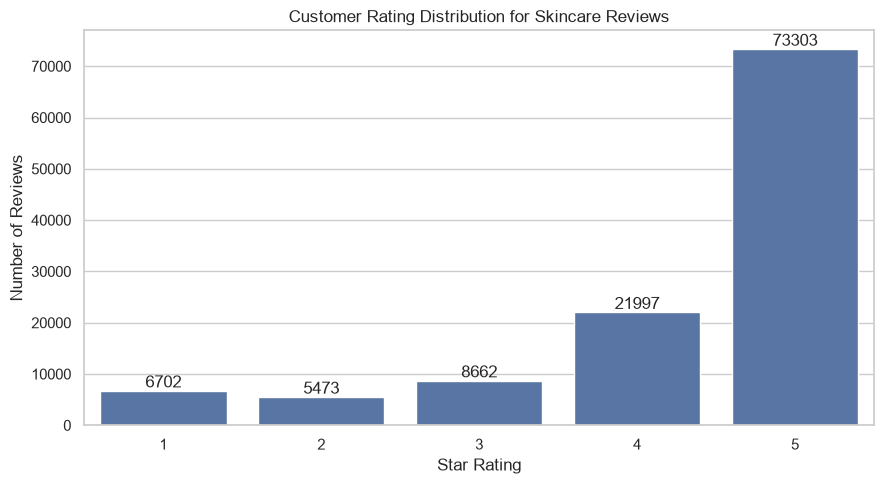

Rating chart and summary saved successfully!


In [6]:
# STEP 3: CUSTOMER RATING DISTRIBUTION

# Count reviews for each star rating
rating_counts = (
    eda_df["rating"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
)

# Calculate percentages
rating_percentages = (
    rating_counts / rating_counts.sum() * 100
).round(2)

# Create a summary table
rating_summary = pd.DataFrame({
    "Review Count": rating_counts,
    "Percentage (%)": rating_percentages
})

print("CUSTOMER RATING SUMMARY")
display(rating_summary)

# Plot rating distribution
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=eda_df,
    x="rating",
    order=[1, 2, 3, 4, 5]
)

# Add count labels to each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Customer Rating Distribution for Skincare Reviews")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()

# Save the chart
plt.savefig(
    output_dir / "rating_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save the summary table
rating_summary.to_csv(
    output_dir / "rating_distribution.csv"
)

print("Rating chart and summary saved successfully!")

In [7]:
# STEP 4: RATING STATISTICS

print("Mean rating:", round(eda_df["rating"].mean(), 2))
print("Median rating:", eda_df["rating"].median())
print("Most common rating:", eda_df["rating"].mode()[0])
print("Lowest rating:", eda_df["rating"].min())
print("Highest rating:", eda_df["rating"].max())

print("\nDetailed statistical summary:")
display(eda_df["rating"].describe())

Mean rating: 4.29
Median rating: 5.0
Most common rating: 5
Lowest rating: 1
Highest rating: 5

Detailed statistical summary:


count    116137.000000
mean          4.289219
std           1.153255
min           1.000000
25%           4.000000
50%           5.000000
75%           5.000000
max           5.000000
Name: rating, dtype: float64

In [8]:
# STEP 5: REVIEW LENGTH ANALYSIS

# Work with the review text
text = eda_df["review_text"].fillna("").astype(str)

# Create text features
eda_df["review_length_chars"] = text.str.len()
eda_df["review_word_count"] = text.str.split().str.len()

# Calculate descriptive statistics
length_summary = eda_df[
    ["review_length_chars", "review_word_count"]
].describe().round(2)

print("REVIEW LENGTH STATISTICS")
display(length_summary)

# Save summary
length_summary.to_csv(
    output_dir / "review_length_statistics.csv"
)

REVIEW LENGTH STATISTICS


,review_length_chars,review_word_count
count,116137.00,116137.00
mean,325.51,61.35
std,231.36,43.37
min,8.00,1.00
25%,184.00,35.00
50%,266.00,50.00
75%,403.00,76.00
max,4353.00,828.00


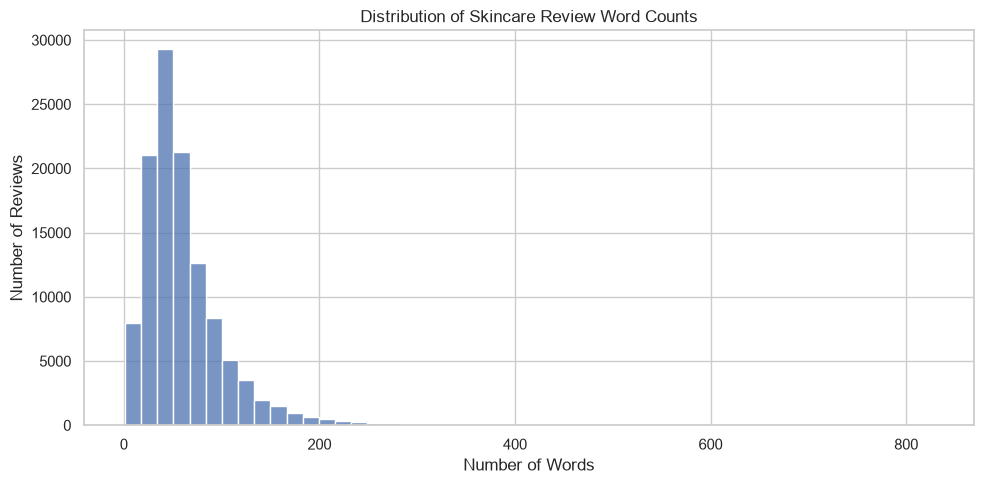

In [9]:
# STEP 6: REVIEW WORD COUNT DISTRIBUTION

plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda_df,
    x="review_word_count",
    bins=50
)

plt.title("Distribution of Skincare Review Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig(
    output_dir / "review_word_count_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Review_Count,Mean_Word_Count,Median_Word_Count
rating,,,
1,6702,53.07,43.0
2,5473,60.13,49.0
3,8662,65.96,55.0
4,21997,66.50,55.0
5,73303,60.10,49.0


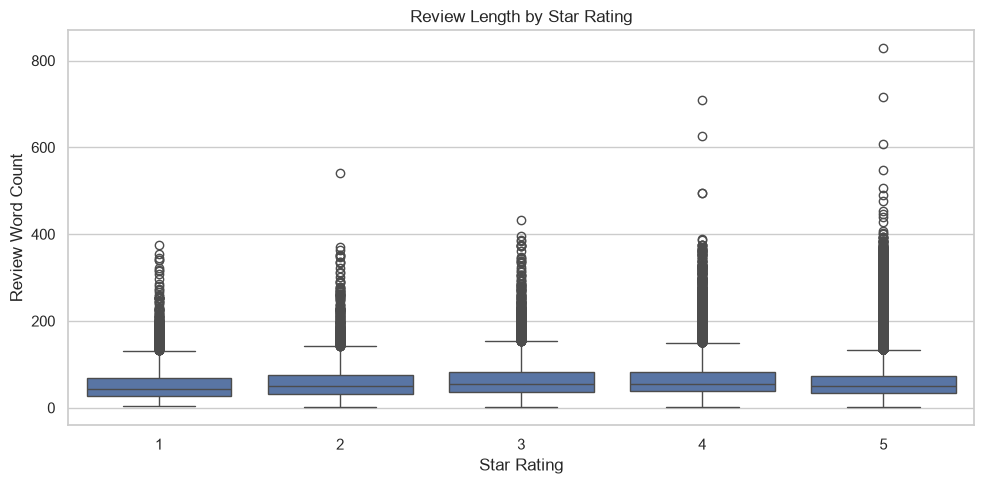

In [10]:
# STEP 7: REVIEW LENGTH BY RATING

length_by_rating = (
    eda_df.groupby("rating", observed=True)
    .agg(
        Review_Count=("review_text", "size"),
        Mean_Word_Count=("review_word_count", "mean"),
        Median_Word_Count=("review_word_count", "median")
    )
    .round(2)
)

display(length_by_rating)

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=eda_df,
    x="rating",
    y="review_word_count"
)

plt.title("Review Length by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Review Word Count")
plt.tight_layout()

plt.savefig(
    output_dir / "review_length_by_rating.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

length_by_rating.to_csv(
    output_dir / "review_length_by_rating.csv"
)

In [11]:
# STEP 8: SPEARMAN CORRELATION

valid_data = eda_df[
    ["rating", "review_word_count"]
].dropna()

correlation, p_value = stats.spearmanr(
    valid_data["rating"],
    valid_data["review_word_count"]
)

print("Spearman correlation:", round(correlation, 4))
print("P-value:", p_value)

if correlation > 0:
    print("Interpretation: A positive monotonic association.")
elif correlation < 0:
    print("Interpretation: A negative monotonic association.")
else:
    print("Interpretation: No monotonic association detected.")

Spearman correlation: -0.021
P-value: 7.791203469355928e-13
Interpretation: A negative monotonic association.


In [12]:
# STEP 9: BRAND-LEVEL EXPLORATORY DATA ANALYSIS

if "brand_name" not in eda_df.columns:
    raise ValueError("brand_name column not found.")

# Use records with a brand name and valid rating
brand_df = eda_df.dropna(
    subset=["brand_name", "rating"]
).copy()

# Summarize ratings for each brand
brand_summary = (
    brand_df.groupby("brand_name")
    .agg(
        Review_Count=("rating", "size"),
        Mean_Rating=("rating", "mean"),
        Median_Rating=("rating", "median"),
        Low_Rating_Count=(
            "rating",
            lambda x: x.isin([1, 2]).sum()
        )
    )
)

# Calculate percentage of low ratings
brand_summary["Low_Rating_Percentage"] = (
    brand_summary["Low_Rating_Count"]
    / brand_summary["Review_Count"] * 100
)

# Avoid unstable comparisons for very small groups
brand_summary = brand_summary[
    brand_summary["Review_Count"] >= 100
].round(2)

brand_summary = brand_summary.sort_values(
    "Mean_Rating",
    ascending=False
)

print("TOP 15 BRANDS BY AVERAGE RATING")
display(brand_summary.head(15))

# Save full summary
brand_summary.to_csv(
    output_dir / "brand_rating_analysis.csv"
)

print("Brand analysis saved successfully!")

TOP 15 BRANDS BY AVERAGE RATING


,Review_Count,Mean_Rating,Median_Rating,Low_Rating_Count,Low_Rating_Percentage
brand_name,,,,,
innisfree,500,4.76,5.0,8,1.60
Gucci,451,4.67,5.0,7,1.55
Benefit Cosmetics,1411,4.67,5.0,28,1.98
MERIT,488,4.64,5.0,12,2.46
GUERLAIN,419,4.62,5.0,10,2.39
Farmacy,2039,4.62,5.0,112,5.49
Clarins,921,4.60,5.0,35,3.80
Wishful,1275,4.60,5.0,47,3.69
iNNBEAUTY PROJECT,388,4.60,5.0,25,6.44


Brand analysis saved successfully!


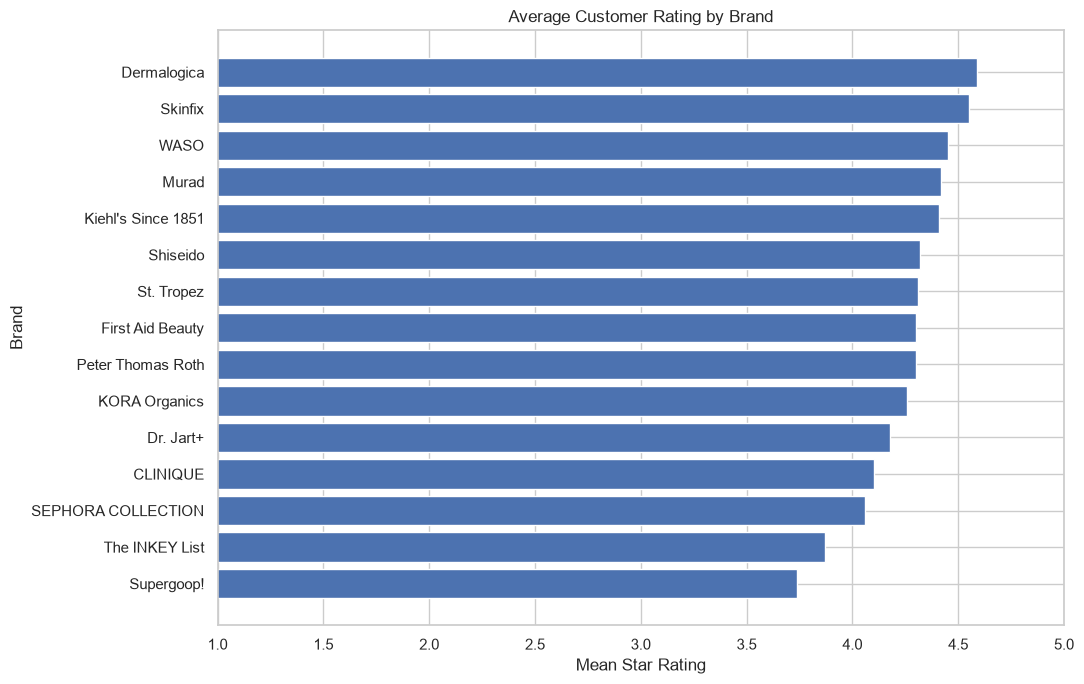

In [13]:
# STEP 10: VISUALIZE BRAND RATINGS

top_brands = (
    brand_summary
    .sort_values("Review_Count", ascending=False)
    .head(15)
    .sort_values("Mean_Rating", ascending=True)
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_brands.index.astype(str),
    top_brands["Mean_Rating"]
)

plt.title("Average Customer Rating by Brand")
plt.xlabel("Mean Star Rating")
plt.ylabel("Brand")
plt.xlim(1, 5)
plt.tight_layout()

plt.savefig(
    output_dir / "brand_mean_ratings.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

TOP 15 BRANDS BY LOW-RATING PERCENTAGE


,Review_Count,Mean_Rating,Low_Rating_Count,Low_Rating_Percentage
brand_name,,,,
Dr. Brandt Skincare,508,3.52,163,32.09
Tatcha,485,3.40,147,30.31
Isle of Paradise,949,3.61,264,27.82
Supergoop!,4124,3.74,990,24.01
TAN-LUXE,470,3.99,93,19.79
The Ordinary,1326,3.95,262,19.76
Slip,427,4.01,82,19.20
The INKEY List,2500,3.87,457,18.28
SEPHORA COLLECTION,4134,4.06,707,17.10


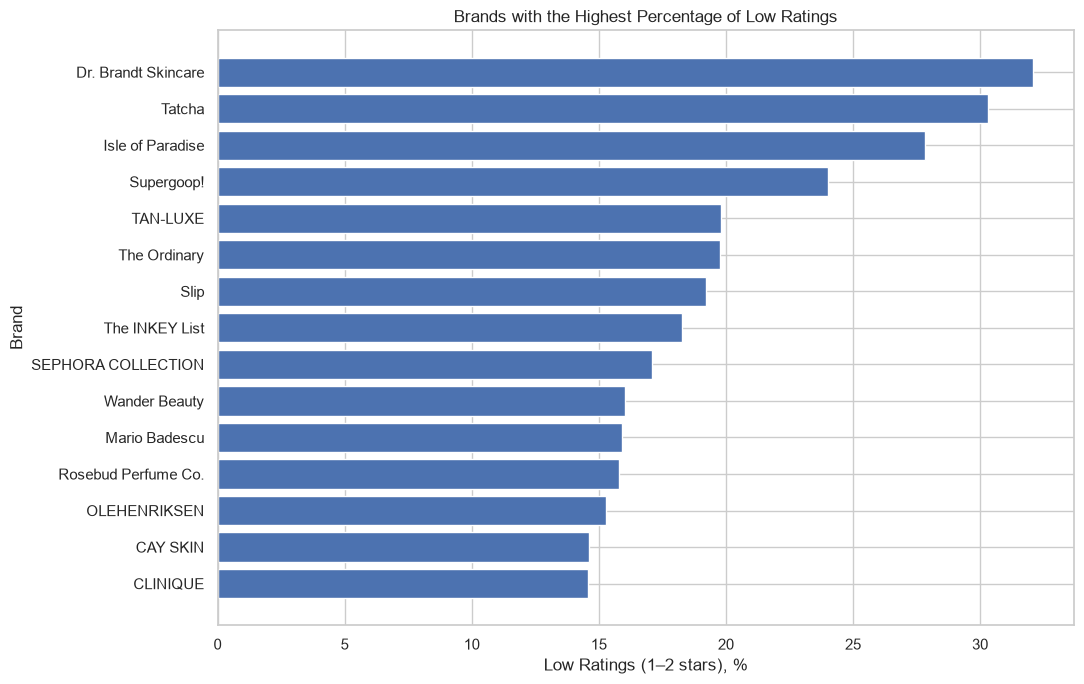

In [14]:
# STEP 11: BRANDS WITH THE HIGHEST LOW-RATING PERCENTAGE

brands_by_low_rating = brand_summary.sort_values(
    ["Low_Rating_Percentage", "Review_Count"],
    ascending=[False, False]
)

print("TOP 15 BRANDS BY LOW-RATING PERCENTAGE")
display(
    brands_by_low_rating[
        [
            "Review_Count",
            "Mean_Rating",
            "Low_Rating_Count",
            "Low_Rating_Percentage"
        ]
    ].head(15)
)

brands_by_low_rating.to_csv(
    output_dir / "brands_by_low_rating_percentage.csv"
)

# Visualize the first 15 brands
low_rating_plot = (
    brands_by_low_rating.head(15)
    .sort_values("Low_Rating_Percentage")
)

plt.figure(figsize=(11, 7))

plt.barh(
    low_rating_plot.index.astype(str),
    low_rating_plot["Low_Rating_Percentage"]
)

plt.title("Brands with the Highest Percentage of Low Ratings")
plt.xlabel("Low Ratings (1–2 stars), %")
plt.ylabel("Brand")
plt.tight_layout()

plt.savefig(
    output_dir / "brand_low_rating_percentage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
# STEP 12: RATING VS RECOMMENDATION ANALYSIS

if "is_recommended" not in eda_df.columns:
    print("is_recommended column not found.")
else:
    # Keep records where both fields are available
    recommendation_df = eda_df.dropna(
        subset=["rating", "is_recommended"]
    ).copy()

    # Create a cross-tabulation
    recommendation_table = pd.crosstab(
        recommendation_df["rating"],
        recommendation_df["is_recommended"]
    )

    print("Rating vs Recommendation Counts:")
    display(recommendation_table)

    # Calculate percentages within each rating
    recommendation_percent = pd.crosstab(
        recommendation_df["rating"],
        recommendation_df["is_recommended"],
        normalize="index"
    ).mul(100).round(2)

    print("\nRecommendation percentages within each rating:")
    display(recommendation_percent)

    # Save tables
    recommendation_table.to_csv(
        output_dir / "rating_recommendation_counts.csv"
    )

    recommendation_percent.to_csv(
        output_dir / "rating_recommendation_percentages.csv"
    )

Rating vs Recommendation Counts:


is_recommended,0.0,1.0
rating,,
1,5676,35
2,4656,148
3,4992,2853
4,592,19289
5,96,65997



Recommendation percentages within each rating:


is_recommended,0.0,1.0
rating,,
1,99.39,0.61
2,96.92,3.08
3,63.63,36.37
4,2.98,97.02
5,0.15,99.85


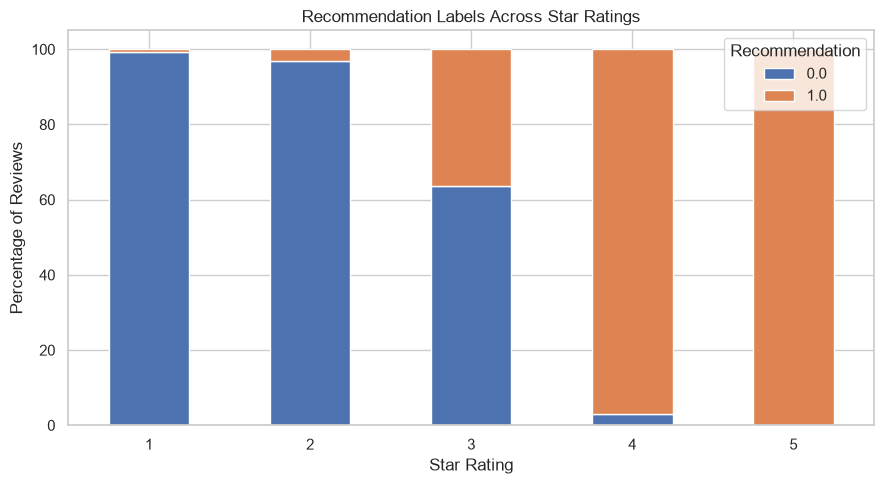

In [16]:
# STEP 13: RECOMMENDATION DISTRIBUTION BY RATING

ax = recommendation_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

ax.set_title("Recommendation Labels Across Star Ratings")
ax.set_xlabel("Star Rating")
ax.set_ylabel("Percentage of Reviews")
ax.legend(title="Recommendation")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    output_dir / "rating_recommendation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# STEP 14: CHI-SQUARE TEST OF ASSOCIATION

from scipy.stats import chi2_contingency

# Remove empty rows or columns if any exist
test_table = recommendation_table.loc[
    recommendation_table.sum(axis=1) > 0,
    recommendation_table.sum(axis=0) > 0
]

if test_table.shape[0] >= 2 and test_table.shape[1] >= 2:

    chi2, p_value, degrees_freedom, expected = (
        chi2_contingency(test_table)
    )

    # Cramer's V measures association strength
    n = test_table.to_numpy().sum()
    min_dimension = min(test_table.shape) - 1

    cramers_v = np.sqrt(
        chi2 / (n * min_dimension)
    ) if min_dimension > 0 and n > 0 else np.nan

    print("Chi-square statistic:", round(chi2, 4))
    print("Degrees of freedom:", degrees_freedom)
    print("P-value:", p_value)
    print("Cramer's V:", round(cramers_v, 4))
    print(
        "Expected cells below 5:",
        int((expected < 5).sum())
    )

    if p_value < 0.05:
        print(
            "Interpretation: There is statistical evidence "
            "of an association between rating and recommendation."
        )
    else:
        print(
            "Interpretation: The test did not find sufficient "
            "evidence of an association."
        )

    if (expected < 5).any():
        print(
            "Note: Some expected cell counts are below 5. "
            "Interpret the chi-square result cautiously."
        )

else:
    print(
        "Not enough non-empty rating and recommendation categories "
        "to perform the chi-square test."
    )

Chi-square statistic: 83829.1817
Degrees of freedom: 4
P-value: 0.0
Cramer's V: 0.8964
Expected cells below 5: 0
Interpretation: There is statistical evidence of an association between rating and recommendation.


In [18]:
# STEP 15: SAVE RECOMMENDATION ANALYSIS

recommendation_summary = {
    "records_analyzed": int(len(recommendation_df)),
    "rating_categories": int(recommendation_table.shape[0]),
    "recommendation_categories": int(recommendation_table.shape[1]),
    "chi_square_statistic": float(chi2),
    "p_value": float(p_value),
    "cramers_v": float(cramers_v)
} if (
    "is_recommended" in eda_df.columns
    and test_table.shape[0] >= 2
    and test_table.shape[1] >= 2
) else {
    "status": "Statistical test could not be completed."
}

with open(
    output_dir / "recommendation_analysis_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(recommendation_summary, f, indent=4)

print("Recommendation analysis saved!")
print("Output folder:", output_dir)

Recommendation analysis saved!
Output folder: C:\Users\ARYAN KATAKDHOND\Downloads\archive\week4_outputs


In [19]:
# STEP 16: FEATURE ENGINEERING

# Work on the review text without overwriting the original
text = eda_df["review_text"].fillna("").astype(str)

# 1. Number of characters
eda_df["review_length_chars"] = text.str.len()

# 2. Number of words
eda_df["review_word_count"] = text.str.split().str.len()

# 3. Approximate sentence count
eda_df["sentence_count"] = np.where(
    text.str.strip().eq(""),
    0,
    text.str.count(r"[.!?]+") + 1
)

# 4. Count exclamation marks
eda_df["exclamation_count"] = text.str.count("!")

# 5. Count question marks
eda_df["question_count"] = text.str.count(r"\?")

# 6. Uppercase letter ratio
letters = text.str.count(r"[A-Za-z]")
uppercase_letters = text.str.count(r"[A-Z]")

eda_df["uppercase_ratio"] = np.divide(
    uppercase_letters,
    letters,
    out=np.zeros(len(eda_df), dtype=float),
    where=letters.to_numpy() > 0
)

# 7. Group ratings for descriptive analysis
eda_df["rating_group"] = pd.cut(
    eda_df["rating"],
    bins=[0, 2, 3, 5],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print("Feature engineering completed!")

new_features = [
    "review_length_chars",
    "review_word_count",
    "sentence_count",
    "exclamation_count",
    "question_count",
    "uppercase_ratio",
    "rating_group"
]

display(eda_df[new_features].head(10))

Feature engineering completed!


,review_length_chars,review_word_count,sentence_count,exclamation_count,question_count,uppercase_ratio,rating_group
0,80,14,2,0,0,0.030769,High
1,264,45,5,0,0,0.018779,High
2,1066,198,14,1,0,0.022892,High
3,123,20,2,2,0,0.010000,High
4,127,22,2,0,0,0.019802,High
5,77,15,3,0,0,0.032787,Low
6,571,114,6,0,0,0.031818,High
7,955,175,12,1,1,0.031788,High
8,596,118,7,1,0,0.013100,High
9,448,82,9,1,0,0.033898,Low


In [20]:
# STEP 17: SKINCARE KEYWORD FEATURES

text_lower = text.str.lower()

# Keywords associated with possible concerns
concern_pattern = (
    r"\b(irritat\w*|burning|burned|rash|redness|"
    r"breakout\w*|dryness|itch\w*)\b"
)

# Keywords associated with possible benefits
benefit_pattern = (
    r"\b(hydrat\w*|moisturi[sz]\w*|smooth\w*|"
    r"glow\w*|soft\w*|sooth\w*|brighten\w*)\b"
)

eda_df["concern_keyword_count"] = (
    text_lower.str.count(concern_pattern)
)

eda_df["benefit_keyword_count"] = (
    text_lower.str.count(benefit_pattern)
)

display(
    eda_df[
        [
            "rating",
            "concern_keyword_count",
            "benefit_keyword_count",
            "review_text"
        ]
    ].head(10)
)

print("Skincare keyword features created.")

,rating,concern_keyword_count,benefit_keyword_count,review_text
0,5,0,0,These are the only pimple patches I’ve used th...
1,4,0,0,One of my ingrown hair turned inflamed and sor...
2,5,6,0,I have tried 10 different acne/blemish patches...
3,4,1,0,"Love these for my mid-size breakouts, specifyi..."
4,4,0,0,Best so far - though still not particularly ef...
5,1,0,0,Not worth it. They arent effective and you can...
6,5,0,0,I purchased these originally because I love Dr...
7,5,0,0,I will be the first to say that the price on t...
8,5,1,0,Both my husband (!) and I have used the dark s...
9,2,1,0,I wish I had read the reviews before purchasin...


Skincare keyword features created.


In [21]:
# STEP 18: FEATURE SUMMARY BY RATING GROUP

feature_summary = (
    eda_df.groupby("rating_group", observed=True)
    .agg(
        Review_Count=("rating", "size"),
        Mean_Word_Count=("review_word_count", "mean"),
        Median_Word_Count=("review_word_count", "median"),
        Mean_Concern_Terms=("concern_keyword_count", "mean"),
        Mean_Benefit_Terms=("benefit_keyword_count", "mean"),
        Mean_Exclamations=("exclamation_count", "mean")
    )
    .round(2)
)

display(feature_summary)

feature_summary.to_csv(
    output_dir / "engineered_feature_summary.csv"
)

,Review_Count,Mean_Word_Count,Median_Word_Count,Mean_Concern_Terms,Mean_Benefit_Terms,Mean_Exclamations
rating_group,,,,,,
Low,12175,56.24,46.0,0.20,0.31,0.34
Medium,8662,65.96,55.0,0.16,0.61,0.26
High,95300,61.58,50.0,0.18,0.93,1.13


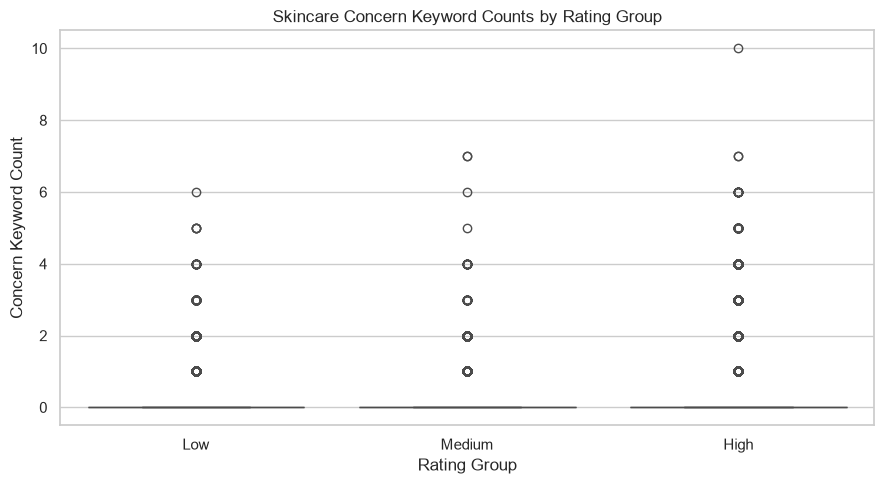

In [22]:
# STEP 19: CONCERN KEYWORDS BY RATING GROUP

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=eda_df,
    x="rating_group",
    y="concern_keyword_count",
    order=["Low", "Medium", "High"]
)

plt.title("Skincare Concern Keyword Counts by Rating Group")
plt.xlabel("Rating Group")
plt.ylabel("Concern Keyword Count")
plt.tight_layout()

plt.savefig(
    output_dir / "concern_keywords_by_rating.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
# STEP 20: TF-IDF TEXT FEATURE EXTRACTION

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import save_npz
import joblib

# Keep records with valid ratings and usable review text
model_data = eda_df.dropna(
    subset=["rating", "review_text"]
).copy()

model_data = model_data[
    model_data["review_text"].astype(str).str.strip().ne("")
].reset_index(drop=True)

# Text and target
X_text = model_data["review_text"].astype(str)
y = model_data["rating"].astype(int)

# Split before fitting TF-IDF to avoid data leakage
train_idx, test_idx = train_test_split(
    np.arange(len(model_data)),
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train_text = X_text.iloc[train_idx]
X_test_text = X_text.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Learn vocabulary and IDF weights from training text only
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=3,
    stop_words="english",
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

print("Training text matrix:", X_train_tfidf.shape)
print("Testing text matrix:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

# Save the sparse matrices and fitted vectorizer
save_npz(
    output_dir / "X_train_tfidf.npz",
    X_train_tfidf
)

save_npz(
    output_dir / "X_test_tfidf.npz",
    X_test_tfidf
)

joblib.dump(
    tfidf,
    output_dir / "tfidf_vectorizer.joblib"
)

y_train.to_csv(output_dir / "y_train.csv", index=False)
y_test.to_csv(output_dir / "y_test.csv", index=False)

print("TF-IDF features and target splits saved successfully!")

ModuleNotFoundError: No module named 'sklearn'

In [24]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 1.7 MB/s eta 0:00:05
   --- ------------------------------------ 0.8/8.2 MB 1.3 MB/s eta 0:00:06
   ----- ---------------------------------- 1.0/8.2 MB 1.2 MB/s eta 0:00:06
   ----- ---------------------------------- 1.0/8.2 MB 1.2 MB/s eta 0:00:06
   ------ --------------------------------- 1.3/8.2 MB 1.2 MB/s eta 0:00:06
   ------- -------------------------------- 1.6/8.2 MB 1.1 MB/s eta 0:00:07
   -------- ------------------------------- 1.8/8.2 MB 1.1 MB/s eta 0:00:06
   -------- ------------------------------- 1.8/8.2 MB 1.1 MB/s eta 0:00:06
   ---------- ----------------------------- 2.1/8.2 MB 973.0 kB/s eta 0:00:07
   ----------- ---------------------------- 2.4/8.2 MB 969.3 kB/s eta 0:00:07
   ----------- ---------------------------- 2.4/8.2 MB 969.3 kB/s eta 0:00:07
   ------------ ----

In [25]:
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler

print("Scikit-learn installed successfully!")
print("Version:", sklearn.__version__)

Scikit-learn installed successfully!
Version: 1.9.1


In [26]:
# STEP 20: TF-IDF TEXT FEATURE EXTRACTION

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import save_npz
import joblib

# Keep records with valid ratings and usable review text
model_data = eda_df.dropna(
    subset=["rating", "review_text"]
).copy()

model_data = model_data[
    model_data["review_text"].astype(str).str.strip().ne("")
].reset_index(drop=True)

# Text and target
X_text = model_data["review_text"].astype(str)
y = model_data["rating"].astype(int)

# Split before fitting TF-IDF to avoid data leakage
train_idx, test_idx = train_test_split(
    np.arange(len(model_data)),
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train_text = X_text.iloc[train_idx]
X_test_text = X_text.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Learn vocabulary and IDF weights from training text only
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=3,
    stop_words="english",
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

print("Training text matrix:", X_train_tfidf.shape)
print("Testing text matrix:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

# Save the sparse matrices and fitted vectorizer
save_npz(
    output_dir / "X_train_tfidf.npz",
    X_train_tfidf
)

save_npz(
    output_dir / "X_test_tfidf.npz",
    X_test_tfidf
)

joblib.dump(
    tfidf,
    output_dir / "tfidf_vectorizer.joblib"
)

y_train.to_csv(output_dir / "y_train.csv", index=False)
y_test.to_csv(output_dir / "y_test.csv", index=False)

print("TF-IDF features and target splits saved successfully!")

Training text matrix: (92909, 5000)
Testing text matrix: (23228, 5000)
Vocabulary size: 5000
TF-IDF features and target splits saved successfully!


In [27]:
# STEP 21: NUMERICAL FEATURE SCALING

from sklearn.preprocessing import StandardScaler

numeric_features = [
    "review_word_count",
    "sentence_count",
    "exclamation_count",
    "question_count",
    "uppercase_ratio",
    "concern_keyword_count",
    "benefit_keyword_count"
]

# Check that the features have been created
available_features = [
    col for col in numeric_features
    if col in model_data.columns
]

if not available_features:
    raise ValueError(
        "No engineered numerical features found. "
        "Run the feature-engineering cells first."
    )

print("Features selected for scaling:")
print(available_features)

# Select features and handle any missing numerical values
X_numeric = (
    model_data[available_features]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

# Use the same train/test row indices as the TF-IDF split
X_numeric_train = X_numeric.iloc[train_idx]
X_numeric_test = X_numeric.iloc[test_idx]

# Fit the scaler only on the training set
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_numeric_train)
X_test_scaled = scaler.transform(X_numeric_test)

print("\nScaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

# Save outputs
np.savez_compressed(
    output_dir / "scaled_numeric_features.npz",
    X_train_scaled=X_train_scaled,
    X_test_scaled=X_test_scaled
)

joblib.dump(
    scaler,
    output_dir / "numeric_scaler.joblib"
)

print("Scaled numerical features saved successfully!")

Features selected for scaling:
['review_word_count', 'sentence_count', 'exclamation_count', 'question_count', 'uppercase_ratio', 'concern_keyword_count', 'benefit_keyword_count']

Scaled training data: (92909, 7)
Scaled testing data: (23228, 7)
Scaled numerical features saved successfully!


In [28]:
# STEP 22: INSPECT TF-IDF VOCABULARY

feature_names = tfidf.get_feature_names_out()
idf_values = tfidf.idf_

tfidf_terms = pd.DataFrame({
    "Term": feature_names,
    "IDF Score": idf_values
}).sort_values(
    "IDF Score",
    ascending=False
)

print("Terms with the highest IDF scores:")
display(tfidf_terms.head(20))

tfidf_terms.to_csv(
    output_dir / "tfidf_vocabulary_and_idf.csv",
    index=False
)

Terms with the highest IDF scores:


,Term,IDF Score
424,bye,8.507561
119,ai,8.264999
3339,que,8.234694
2581,masque,8.176707
2049,je,8.176707
1181,est,8.148927
2999,pekee,8.135321
230,bader,8.135321
2349,lo,8.121898
3138,prima,8.121898


In [29]:
# STEP 23: SAVE THE WEEK 4 FEATURE-ENGINEERED DATASET

from datetime import datetime
import json

# Save the original review data with the newly engineered features
feature_file = output_dir / "week4_feature_engineered_reviews.csv"

eda_df.to_csv(feature_file, index=False)

print("Feature-engineered dataset saved successfully!")
print("File:", feature_file)
print("Rows:", eda_df.shape[0])
print("Columns:", eda_df.shape[1])

Feature-engineered dataset saved successfully!
File: C:\Users\ARYAN KATAKDHOND\Downloads\archive\week4_outputs\week4_feature_engineered_reviews.csv
Rows: 116137
Columns: 30


In [30]:
# STEP 24: CREATE THE WEEK 4 SUMMARY

summary = {
    "project": "Customer Sentiment Analysis of Skincare Product Reviews",
    "task": "Week 4 - Exploratory Data Analysis and Feature Engineering",
    "generated_at": datetime.now().isoformat(timespec="seconds"),
    "dataset_rows": int(eda_df.shape[0]),
    "dataset_columns": int(eda_df.shape[1]),
    "mean_rating": round(float(eda_df["rating"].mean()), 3),
    "median_rating": float(eda_df["rating"].median()),
    "mean_review_word_count": round(
        float(eda_df["review_word_count"].mean()), 2
    ),
    "median_review_word_count": float(
        eda_df["review_word_count"].median()
    ),
    "rating_distribution": {
        str(int(rating)): int(count)
        for rating, count in eda_df["rating"].value_counts().sort_index().items()
    },
    "features_created": [
        col for col in [
            "review_length_chars",
            "review_word_count",
            "sentence_count",
            "exclamation_count",
            "question_count",
            "uppercase_ratio",
            "rating_group",
            "concern_keyword_count",
            "benefit_keyword_count"
        ] if col in eda_df.columns
    ],
    "tfidf_vocabulary_size": int(len(tfidf.vocabulary_))
}

summary_path = output_dir / "week4_eda_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

print("Week 4 summary saved!")
print(json.dumps(summary, indent=4))

Week 4 summary saved!
{
    "project": "Customer Sentiment Analysis of Skincare Product Reviews",
    "task": "Week 4 - Exploratory Data Analysis and Feature Engineering",
    "generated_at": "2026-10-19T11:12:53",
    "dataset_rows": 116137,
    "dataset_columns": 30,
    "mean_rating": 4.289,
    "median_rating": 5.0,
    "mean_review_word_count": 61.35,
    "median_review_word_count": 50.0,
    "rating_distribution": {
        "1": 6702,
        "2": 5473,
        "3": 8662,
        "4": 21997,
        "5": 73303
    },
    "features_created": [
        "review_length_chars",
        "review_word_count",
        "sentence_count",
        "exclamation_count",
        "question_count",
        "uppercase_ratio",
        "rating_group",
        "concern_keyword_count",
        "benefit_keyword_count"
    ],
    "tfidf_vocabulary_size": 5000
}


In [31]:
# STEP 25: EXPORT DESCRIPTIVE STATISTICS

descriptive_stats = eda_df.describe(include="all").T

display(descriptive_stats.head(20))

descriptive_stats.to_csv(
    output_dir / "week4_descriptive_statistics.csv"
)

print("Descriptive statistics saved successfully!")

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
unnamed_0,116137.0,NaN,NaN,NaN,58136.731627,33562.49644,0.0,29070.0,58144.0,87200.0,116261.0
author_id,116137,84022,2048600043,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,116137.0,NaN,NaN,NaN,4.289219,1.153255,1.0,4.0,5.0,5.0,5.0
is_recommended,104334.0,NaN,NaN,NaN,0.846531,0.36044,0.0,1.0,1.0,1.0,1.0
helpfulness,59784.0,NaN,NaN,NaN,0.768181,0.319655,0.0,0.666667,0.933333,1.0,1.0
total_feedback_count,116137.0,NaN,NaN,NaN,4.313518,18.940508,0.0,0.0,1.0,4.0,3158.0
total_neg_feedback_count,116137.0,NaN,NaN,NaN,0.924744,5.561405,0.0,0.0,0.0,1.0,500.0
total_pos_feedback_count,116137.0,NaN,NaN,NaN,3.388774,16.070473,0.0,0.0,0.0,3.0,2763.0
submission_time,116137,4880,2021-04-22,417,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_text,116137,110410,I received this in a sample. I have alot of ac...,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Descriptive statistics saved successfully!


In [32]:
# STEP 26: FINAL WEEK 4 VALIDATION

required_features = [
    "review_word_count",
    "sentence_count",
    "exclamation_count",
    "question_count",
    "uppercase_ratio",
    "rating_group",
    "concern_keyword_count",
    "benefit_keyword_count"
]

missing_features = [
    col for col in required_features
    if col not in eda_df.columns
]

assert not missing_features, (
    f"Missing engineered features: {missing_features}"
)

assert eda_df["rating"].dropna().between(1, 5).all()
assert eda_df["review_word_count"].notna().all()
assert X_train_tfidf.shape[0] == len(y_train)
assert X_test_tfidf.shape[0] == len(y_test)

print("All final validation checks passed!")
print("Final dataset shape:", eda_df.shape)
print("TF-IDF training shape:", X_train_tfidf.shape)
print("TF-IDF testing shape:", X_test_tfidf.shape)
print("Output folder:", output_dir)

All final validation checks passed!
Final dataset shape: (116137, 30)
TF-IDF training shape: (92909, 5000)
TF-IDF testing shape: (23228, 5000)
Output folder: C:\Users\ARYAN KATAKDHOND\Downloads\archive\week4_outputs


In [33]:
# STEP 27: OUTPUT FILE INVENTORY

output_files = sorted(
    p for p in output_dir.iterdir()
    if p.is_file()
)

for file in output_files:
    print(f"{file.name}  |  {file.stat().st_size:,} bytes")

print(f"\nTotal files saved: {len(output_files)}")

brand_low_rating_percentage.png  |  157,571 bytes
brand_mean_ratings.png  |  160,034 bytes
brand_rating_analysis.csv  |  2,857 bytes
brands_by_low_rating_percentage.csv  |  2,857 bytes
concern_keywords_by_rating.png  |  82,831 bytes
engineered_feature_summary.csv  |  230 bytes
numeric_scaler.joblib  |  1,119 bytes
rating_distribution.csv  |  105 bytes
rating_distribution.png  |  88,714 bytes
rating_recommendation_comparison.png  |  84,858 bytes
rating_recommendation_counts.csv  |  77 bytes
rating_recommendation_percentages.csv  |  87 bytes
recommendation_analysis_summary.json  |  207 bytes
review_length_by_rating.csv  |  150 bytes
review_length_by_rating.png  |  109,074 bytes
review_length_statistics.csv  |  181 bytes
review_word_count_distribution.png  |  82,993 bytes
scaled_numeric_features.npz  |  853,710 bytes
tfidf_vectorizer.joblib  |  197,270 bytes
tfidf_vocabulary_and_idf.csv  |  146,515 bytes
week4_data_quality_profile.csv  |  760 bytes
week4_descriptive_statistics.csv  |  2,8